# Challenge 2 – Classification into screws and nuts

**Task.** Classify every segmented part as screw or nut, and report the number of screws and of nuts in each image. Long fasteners with a head (screws, bolts, nails) are _screws_.

**Requirements:**
- Extract as many descriptors as you find useful (shape, topology, moments. . . ) and study them: distribution per class, discriminative power, invariance to rotation and scale, redundancy. Justify the subset you keep.
- Use at least N classification methodologies of different nature (e.g. rules / decision trees, k-NN, LDA/QDA, logistic regression, SVM, ensembles. . . ) and justify their use and their hyper-parameters.
- Discuss how each classifier behaves when the segmentation is imperfect (false positives, lost holes, merged parts).

## 1. Feature extraction

First of all, we need to decide what features we want to extract from the segmented parts. The following list contains some possible descriptors that can be used for classification:


In the braclets, invariance by T:translation, R:rotation, S:scale is indicated.
List of possible descriptors:
- Shape
    - Area/size {TR}
        - Not really discriminative, as there are small screws and big nuts.
    - Perimeter {TR}
        - Not really discriminative, as there are small screws and big nuts.
    - Circularity {TRS}
        - Discriminative, as screws are elongated and nuts are more circular.
    - Eccentricity {TRS}
        - Discriminative, as screws are elongated and nuts are more circular.
    - Solidity (concavity) {TRS}
        - Very discriminative, as screws have concave parts (the area from the head to the peak) and nuts are convex.
    - Simmetries {TRS}
        - Discriminative:
            - Screws have none to a single axis of symmetry (the axis that goes from the head to the peak, if we don't consider the thread).
            - Nuts have multiple axes of symmetry.
    - Vertex, edge, curvature {TR}
        - Discriminative, but in two and opposite cases:
            -  If we consider the thread, screws have many edges and vertices, while nuts have few.
            - If we don't consider the thread, screws have few edges and vertices, while nuts have many.
            - The decision depends on how much the post-processing of the first challenge eroded the threads.
    - Circle structure {TRS}
        - Discriminative, as the Hough transform can detect the circular holes in the nuts.
- Topological Descriptors
    - Euler number {TRS}
        - Very discriminative, as screws have a single connected component, while nuts have two (the outer and the inner). Note: the mask of the screws must be completely filled.
- Moments
    - Hu moments {TRS}
        - Discriminative, as they are invariant to rotation and scale, and can be used to distinguish between screws and nuts.
        - Still, they might be an overkill, as the other descriptors are already discriminative enough. Considering it as a last resort.

In [10]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage import measure
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ANNOTATIONS_DIR = Path("annotations")

OUTPUT_DIR = Path("outputs")

C1_OUTPUT_DIR = OUTPUT_DIR / "challenge_1_results"
C2_OUTPUT_DIR = OUTPUT_DIR / "challenge_2_results"
C2_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IOU_MATCHING_THRESHOLD = 0.5  # minimum IoU to match a predicted mask with a ground-truth part
ECCENTRICITY_THRESHOLD = 0.515  # parts with lower eccentricity are classified as nuts


### 1.2. Hough Transform for hole/circle detection

In [11]:
def check_circle_structure(crop_mask: np.ndarray) -> bool:
    """
    Check whether the segmented part contains a circular structure (hole) using the Hough transform.

    Args:
        crop_mask (np.ndarray): 16-bit mask of the segmented part.

    Returns:
        bool: True if a circular structure is detected, False otherwise.
    """

    if crop_mask is None or crop_mask.size == 0 or crop_mask.max() == 0:
        return False

    crop_uint8 = cv2.normalize(crop_mask, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    # Smooth the binary edges so that the gradient votes converge towards the centre
    blurred = cv2.GaussianBlur(crop_uint8, (9, 9), 2)

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=60,
        param1=60,  # upper Canny threshold
        param2=22,  # accumulator threshold: lower values detect more circles
        minRadius=20,
        maxRadius=110
    )

    return circles is not None

def check_symmetry(crop_mask: np.ndarray, iou_threshold: float = 0.85, step_deg: int = 2) -> tuple[int, float]:
    """
    Count the symmetry axes of a part and compute its mean symmetry score.

    Args:
        crop_mask (np.ndarray): Mask of the part (16-bit or 8-bit).
        iou_threshold (float): IoU threshold (0.0-1.0) above which a peak is counted as a symmetry axis.
        step_deg (int): Angular step of the scan, in degrees.

    Returns:
        tuple[int, float]:
            - num_axes (int): Number of symmetry axes detected.
            - symmetry_balance (float): Mean IoU between the mask and its mirrored copy over all
              scanned angles (0.0 - 1.0).
    """
    if crop_mask is None or crop_mask.size == 0 or crop_mask.max() == 0:
        return 0, 0.0

    binary = (crop_mask > 0).astype(np.uint8)

    M = cv2.moments(binary)
    if M['m00'] == 0:
        return 0, 0.0

    cx = M['m10'] / M['m00']
    cy = M['m01'] / M['m00']

    # Move the centroid to the image centre so that rotations are about the centroid
    h, w = binary.shape
    center_x, center_y = w / 2.0, h / 2.0
    tx = center_x - cx
    ty = center_y - cy

    T = np.float32([[1, 0, tx], [0, 1, ty]])
    centered_mask = cv2.warpAffine(binary, T, (w, h), flags=cv2.INTER_NEAREST)

    # For each angle, compare the rotated mask with its mirror image (IoU)
    angles = np.arange(0, 180, step_deg)
    ious = []

    for angle in angles:
        R = cv2.getRotationMatrix2D((center_x, center_y), angle, 1.0)
        rotated = cv2.warpAffine(centered_mask, R, (w, h), flags=cv2.INTER_NEAREST)

        flipped = cv2.flip(rotated, 1)

        intersection = np.logical_and(rotated, flipped).sum()
        union = np.logical_or(rotated, flipped).sum()

        iou = intersection / union if union > 0 else 0.0
        ious.append(iou)

    ious = np.array(ious)

    # A symmetry axis shows up as a local maximum of the IoU curve above the threshold
    num_axes = 0
    n = len(ious)
    for i in range(n):
        prev_idx = (i - 1) % n
        next_idx = (i + 1) % n
        if ious[i] >= iou_threshold and ious[i] > ious[prev_idx] and ious[i] >= ious[next_idx]:
            num_axes += 1

    # 0.0 = fully asymmetric, 1.0 = perfectly symmetric
    symmetry_balance = float(np.mean(ious))

    return num_axes, symmetry_balance



### 1.3 Feature extraction function
This code:
- extracts the features from the mask components and matches them to the ground truth annotations using IoU;
- extract shape and topological descriptors from the masks using `skimage.measure.regionprops` and custom functions for circularity and symmetry;
- returns a DataFrame with the extracted features and the matched ground truth type (screw/nut)


In [12]:
def extract_part_features(mask_16bit: np.ndarray, image_stem: str) -> pd.DataFrame:
    regions = measure.regionprops(mask_16bit)

    if not regions:
        print(f"No regions found in mask for image {image_stem}.")
        return pd.DataFrame()

    properties = ['label', 'area', 'perimeter', 'eccentricity', 'solidity', 'euler_number']
    features_df = pd.DataFrame(measure.regionprops_table(mask_16bit, properties=properties))

    eps = 1e-6
    features_df['circularity'] = (4 * np.pi * features_df['area']) / (features_df['perimeter'] ** 2 + eps)

    is_circle_list = []
    num_axes_list = []
    symmetry_balance_list = []

    for region in regions:
        crop_bool = region.image
        is_circle_list.append(check_circle_structure(crop_bool))
        num_axes, balance = check_symmetry(crop_bool)
        num_axes_list.append(num_axes)
        symmetry_balance_list.append(balance)

    features_df['is_circle'] = is_circle_list
    features_df['num_axes'] = num_axes_list
    features_df['symmetry_balance'] = symmetry_balance_list

    # Match each predicted region to a ground-truth part by IoU
    gt_mask_path = ANNOTATIONS_DIR / f"{image_stem}_labels.png"
    annotation_csv_path = ANNOTATIONS_DIR / "parts.csv"

    if gt_mask_path.exists() and annotation_csv_path.exists():
        gt_mask_16bit = cv2.imread(str(gt_mask_path), cv2.IMREAD_UNCHANGED)
        annotations_df = pd.read_csv(annotation_csv_path)

        # Normalise the image names in the annotations so they match image_stem
        annotations_df['image_clean'] = annotations_df['image'].apply(
            lambda x: Path(x).stem.replace(r"(_labels?|_label_image|\.png|\.jpg|\.tiff?)$", "")
        )
        df_image_annotations = annotations_df[annotations_df['image_clean'] == image_stem]

        gt_regions = measure.regionprops(gt_mask_16bit)

        matched_types = []
        matched_gt_ids = []

        for region in regions:
            pred_binary = (mask_16bit == region.label)

            best_iou = 0.0
            best_gt_label = None

            for gt_region in gt_regions:
                gt_binary = (gt_mask_16bit == gt_region.label)

                intersection = np.logical_and(pred_binary, gt_binary).sum()
                union = np.logical_or(pred_binary, gt_binary).sum()

                iou = intersection / union if union > 0 else 0.0

                if iou > best_iou:
                    best_iou = iou
                    best_gt_label = gt_region.label

            if best_iou >= IOU_MATCHING_THRESHOLD and best_gt_label is not None:
                gt_info = df_image_annotations[df_image_annotations['part_id'] == best_gt_label]
                if not gt_info.empty:
                    matched_types.append(gt_info.iloc[0]['type'])
                    matched_gt_ids.append(best_gt_label)
                else:
                    matched_types.append(np.nan)
                    matched_gt_ids.append(np.nan)
            else:
                # No ground-truth part matched: false positive
                matched_types.append(np.nan)
                matched_gt_ids.append(np.nan)

        features_df['type'] = matched_types
        features_df['gt_part_id'] = matched_gt_ids
    else:
        if not gt_mask_path.exists():
            print(f"Warning: ground-truth mask not found: {gt_mask_path.name}")
        features_df['type'] = np.nan
        features_df['gt_part_id'] = np.nan

    features_df.insert(0, 'image_stem', image_stem)
    return features_df

1.4 Feature extraction for all images

In [13]:
# Features are extracted from the PNG masks generated in challenge 1
mask_files = sorted(list(C1_OUTPUT_DIR.glob("*.png")))

print(f"Found {len(mask_files)} mask files for feature extraction.")

all_features_list = []

for mask_path in mask_files:
    mask_array = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)

    if mask_array is None:
        print(f"Warning: could not read file {mask_path.name}")
        continue

    image_stem = mask_path.stem.replace("_label_image", "")

    df_single = extract_part_features(mask_array, image_stem=image_stem)

    if not df_single.empty:
        all_features_list.append(df_single)
        print(f" Processed: {mask_path.name} -> extracted {len(df_single)} components.")

if all_features_list:
    df_dataset = pd.concat(all_features_list, ignore_index=True)

    csv_output_path = C2_OUTPUT_DIR / "extracted_features.csv"
    df_dataset.to_csv(csv_output_path, index=False)

    print("\n Feature extraction completed.")
    print(f"Dataset saved to: {csv_output_path}")
    print(f"Final dataset shape: {df_dataset.shape} (rows/components x columns/features)")

    display(df_dataset)
else:
    print("No features extracted. Check the masks and the extraction code.")



Found 10 mask files for feature extraction.
 Processed: screws_026_label_image.png -> extracted 8 components.
 Processed: screws_027_label_image.png -> extracted 8 components.
 Processed: screws_028_label_image.png -> extracted 8 components.
 Processed: screws_029_label_image.png -> extracted 8 components.
 Processed: screws_040_label_image.png -> extracted 10 components.
 Processed: screws_041_label_image.png -> extracted 9 components.
 Processed: screws_042_label_image.png -> extracted 10 components.
 Processed: screws_061_label_image.png -> extracted 8 components.
 Processed: screws_063_label_image.png -> extracted 8 components.
 Processed: screws_119_label_image.png -> extracted 9 components.

 Feature extraction completed.
Dataset saved to: outputs/challenge_2_results/extracted_features.csv
Final dataset shape: (86, 13) (rows/components x columns/features)


,image_stem,label,area,perimeter,eccentricity,solidity,euler_number,circularity,is_circle,num_axes,symmetry_balance,type,gt_part_id
0,screws_026,1,13341.0,691.126984,0.953661,0.661362,1,0.350980,False,2,0.350030,screw,3.0
1,screws_026,2,11421.0,803.820418,0.986028,0.619360,1,0.222124,False,1,0.202944,screw,4.0
2,screws_026,3,11333.0,771.653896,0.986214,0.638119,1,0.239172,False,1,0.269948,screw,5.0
3,screws_026,4,2667.0,279.078210,0.174912,0.863386,0,0.430310,False,14,0.896262,nut,8.0
4,screws_026,5,2713.0,278.249783,0.212081,0.871227,0,0.440342,False,14,0.909059,nut,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,screws_119,5,4866.0,416.717821,0.162916,0.804963,0,0.352126,True,7,0.861768,nut,4.0
82,screws_119,6,2771.0,276.936075,0.138595,0.878846,0,0.454033,False,25,0.911534,nut,5.0
83,screws_119,7,24976.0,1051.187950,0.092737,0.741084,0,0.284035,True,6,0.874296,nut,3.0
84,screws_119,8,11300.0,808.305699,0.987036,0.614264,1,0.217339,False,1,0.200009,screw,2.0


### 1.5 Feature analysis

Scatterplots that might be interesting:
- Eccentricity vs. Area
- Eccentricity vs. Perimeter
- Area vs. Perimeter
- Solidity vs Euler number
- Eccentricity vs Circularity



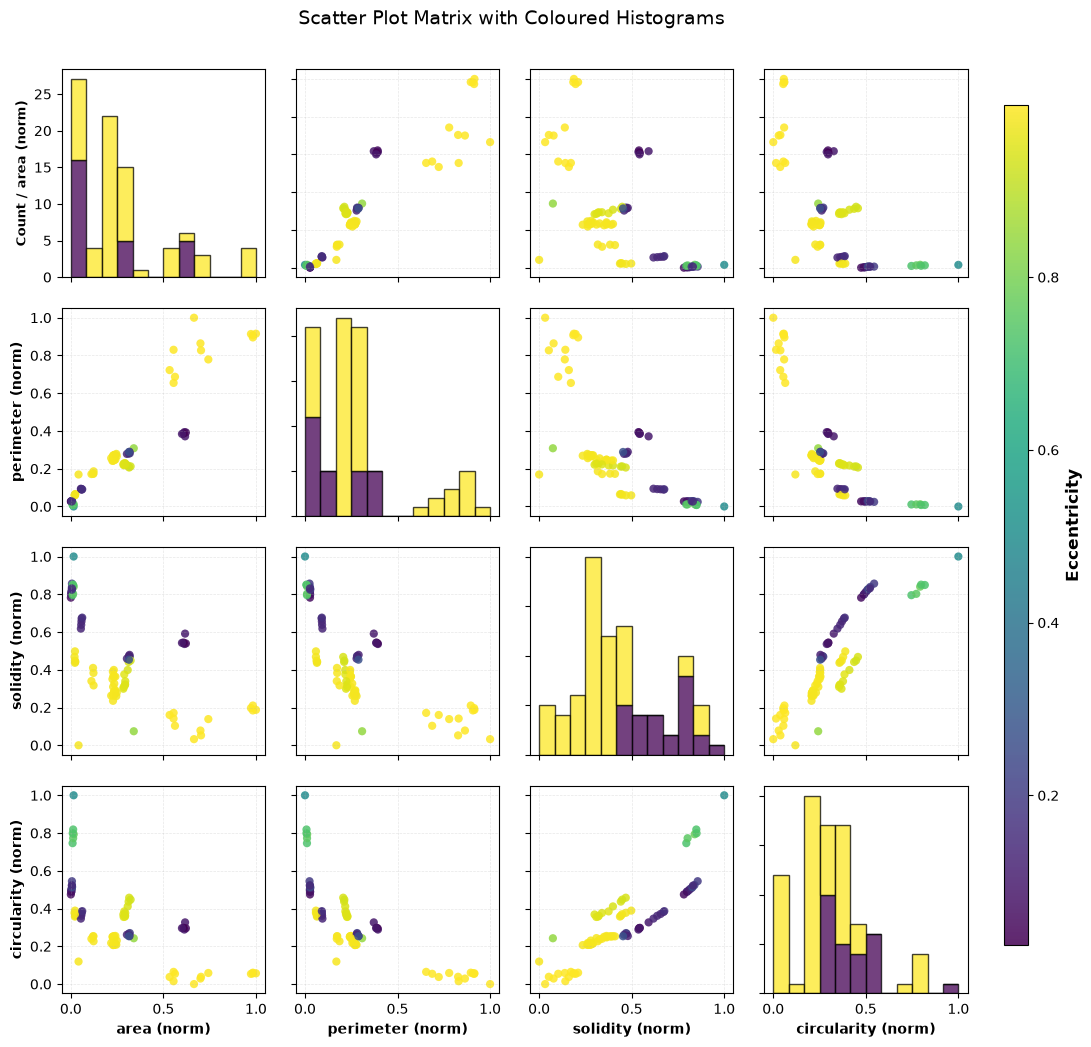

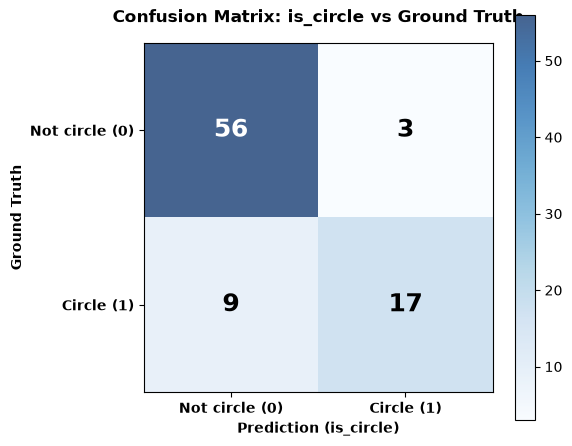

--- EVALUATION METRICS ---
True Positives (TP)  : 17
True Negatives (TN)  : 56
False Positives (FP) : 3
False Negatives (FN) : 9
--------------------------------
Accuracy    : 85.88%
Precision   : 85.00%
Recall      : 65.38%
Specificity : 94.92%
F1-Score    : 73.91%


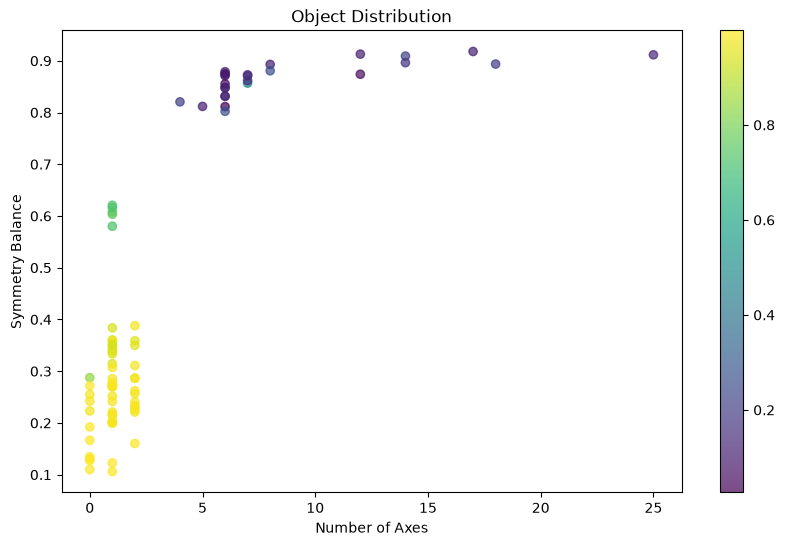

In [14]:
# Min-max normalisation of the features, for plotting
df_plot = df_dataset.copy()
features = ['area', 'perimeter', 'solidity', 'circularity']

for col in features:
    min_val = df_plot[col].min()
    max_val = df_plot[col].max()
    df_plot[col] = (df_plot[col] - min_val) / (max_val - min_val)

n_feats = len(features)
fig, axes = plt.subplots(n_feats, n_feats, figsize=(12, 12))
ecc = df_plot['eccentricity']

# Split nuts/screws by the eccentricity threshold, only to colour the histograms
is_nut = df_plot['eccentricity'] < ECCENTRICITY_THRESHOLD

sc = None


for i in range(n_feats):
    feature_y = features[i]
    for j in range(n_feats):
        feature_x = features[j]
        ax = axes[i, j]

        if i == j:
            ax.hist(
                [df_plot.loc[is_nut, feature_x], df_plot.loc[~is_nut, feature_x]],
                bins=12,
                stacked=True,
                color=['#440154', '#fde725'],  # purple: nuts, yellow: screws
                edgecolor='black',
                alpha=0.75
            )
            ax.set_xlim(-0.05, 1.05)
        else:
            sc = ax.scatter(
                df_plot[feature_x],
                df_plot[feature_y],
                c=ecc,
                cmap='viridis',
                alpha=0.85,
                edgecolors='none',
                s=35
            )
            ax.grid(True, linestyle='--', alpha=0.3)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xlim(-0.05, 1.05)

        lbl_x = f"{feature_x} (norm)"
        lbl_y = f"{feature_y} (norm)"

        if i == n_feats - 1:
            ax.set_xlabel(lbl_x, fontsize=10, fontweight='bold')
        else:
            ax.set_xticklabels([])

        if j == 0:
            if i == 0:
                ax.set_ylabel(f"Count / {lbl_y}", fontsize=9, fontweight='bold')
            else:
                ax.set_ylabel(lbl_y, fontsize=10, fontweight='bold')
        else:
            ax.set_yticklabels([])

fig.subplots_adjust(right=0.88, hspace=0.15, wspace=0.15)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])

if sc is not None:
    cbar = fig.colorbar(sc, cax=cbar_ax)
    cbar.set_label('Eccentricity', fontsize=12, fontweight='bold')

plt.suptitle("Scatter Plot Matrix with Coloured Histograms", y=0.93, fontsize=14)
plt.show()

# Ground truth: nut = 1, screw = 0
df_dataset['ground_truth'] = df_dataset['type'].map({'nut': 1, 'screw': 0})

# Drop parts without ground truth (false positives) or without is_circle
df_clean = df_dataset.dropna(subset=['ground_truth', 'is_circle'])

y_true = df_clean['ground_truth'].astype(int)
y_pred = df_clean['is_circle'].astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(cm, cmap=plt.cm.Blues, alpha=0.75)

fig.colorbar(cax)

labels = ['Not circle (0)', 'Circle (1)']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.set_yticklabels(labels, fontsize=10, fontweight='bold')

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        # White text on dark cells
        text_color = 'white' if val > cm.max() / 2 else 'black'
        ax.text(j, i, f"{val}", ha='center', va='center',
                color=text_color, fontsize=18, fontweight='bold')

plt.title('Confusion Matrix: is_circle vs Ground Truth', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Prediction (is_circle)', fontsize=10, fontweight='bold')
plt.ylabel('Ground Truth', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("--- EVALUATION METRICS ---")
print(f"True Positives (TP)  : {tp}")
print(f"True Negatives (TN)  : {tn}")
print(f"False Positives (FP) : {fp}")
print(f"False Negatives (FN) : {fn}")
print("-" * 32)
print(f"Accuracy    : {accuracy:.2%}")
print(f"Precision   : {precision:.2%}")
print(f"Recall      : {recall:.2%}")
print(f"Specificity : {specificity:.2%}")
print(f"F1-Score    : {f1:.2%}")

# Number of symmetry axes vs symmetry balance, coloured by eccentricity
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_clean['num_axes'], df_clean['symmetry_balance'], c=df_clean['eccentricity'], cmap='viridis', alpha=0.7)
plt.colorbar(scatter)
plt.xlabel('Number of Axes')
plt.ylabel('Symmetry Balance')
plt.title('Object Distribution')
plt.show()


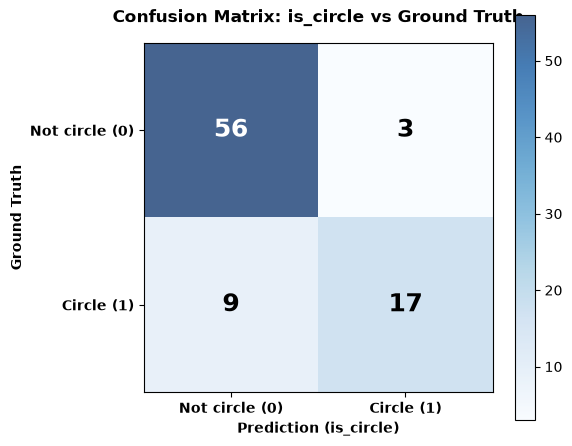

--- EVALUATION METRICS ---
True Positives (TP)  : 17
True Negatives (TN)  : 56
False Positives (FP) : 3
False Negatives (FN) : 9
--------------------------------
Accuracy    : 85.88%
Precision   : 85.00%
Recall      : 65.38%
Specificity : 94.92%
F1-Score    : 73.91%


In [15]:
# Ground truth: nut = 1, screw = 0
df_dataset['ground_truth'] = df_dataset['type'].map({'nut': 1, 'screw': 0})

# Drop parts without ground truth (false positives) or without is_circle
df_clean = df_dataset.dropna(subset=['ground_truth', 'is_circle'])

y_true = df_clean['ground_truth'].astype(int)
y_pred = df_clean['is_circle'].astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(cm, cmap=plt.cm.Blues, alpha=0.75)

fig.colorbar(cax)

labels = ['Not circle (0)', 'Circle (1)']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.set_yticklabels(labels, fontsize=10, fontweight='bold')

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        # White text on dark cells
        text_color = 'white' if val > cm.max() / 2 else 'black'
        ax.text(j, i, f"{val}", ha='center', va='center',
                color=text_color, fontsize=18, fontweight='bold')

plt.title('Confusion Matrix: is_circle vs Ground Truth', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Prediction (is_circle)', fontsize=10, fontweight='bold')
plt.ylabel('Ground Truth', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("--- EVALUATION METRICS ---")
print(f"True Positives (TP)  : {tp}")
print(f"True Negatives (TN)  : {tn}")
print(f"False Positives (FP) : {fp}")
print(f"False Negatives (FN) : {fn}")
print("-" * 32)
print(f"Accuracy    : {accuracy:.2%}")
print(f"Precision   : {precision:.2%}")
print(f"Recall      : {recall:.2%}")
print(f"Specificity : {specificity:.2%}")
print(f"F1-Score    : {f1:.2%}")

## 2. Classification
By a quick analysis of the features extracted, we can see that some of them are more discriminative than others. For example, we can see that the eccentricity is very discriminative alone, it creates two very distinct clusters, one with maximum e. of ~33% and the other with a minimum of ~69%.

1. **Rule-based classification using had crafted thresholds.** This approach was included to show the possibility of creating an (almost) completely unsupervised classification.
By the previous data analysis, we can see that the eccentricity is very discriminative alone, it creates two very distinct clusters, one with maximum e. of ~34% and the other with a minimum of ~69%. These percentages come from a previous run on annotated labelled, but the results on the derived masks are very similar.
2. **Test split.** With GroupKFold, training and test sets are created. Using GroupKFold prevents data leakage and ensures that the model is evaluated on unseen images.
3. **Trained models.** Different kinds of models are trained on these datasets with three different feature sets:
    - **Feature set A:** all the features except Eccentricity, to see if the other features can be discriminative enough.
    - **Feature set B:** only Eccentricity, as it was already seen to be very discriminative just with a simple threshold.
    - **Feature set C:** only the symmetry descriptors (number of axes and symmetry balance), alone and combined, without eccentricity or any other feature, to see how far symmetry alone can go. Evaluated in section 2.1.
4. **Evaluation.** The models are evaluated using accuracy and F1-score, and the results are compared in a summary table, together with the rule-based classification.

**Expectation:** We expect that the rule-based classification will perform near 100% accuracy, as the threshold was derived from the data analysis. The other models might perform similarly or slightly worse, depending on their ability to learn from the features provided.

**Models:**
- Decision Tree Classifier
    - **Why?** Interpretable, rule-based model that learns data-driven thresholds, in the same spirit as the hand-crafted eccentricity rule. It needs no feature scaling and copes with features of different nature (continuous ones and the discrete Euler number). Hyper-parameters are left at their defaults (fully grown tree, `random_state=42` for reproducibility), since the classes are almost separable and only a few splits are needed.
- Logistic Regression
    - **Why?** Linear and probabilistic baseline: if a linear boundary is enough, a more complex model is not justified, and its coefficients show which features matter. Features are standardised, because area and perimeter are in pixels while the others are dimensionless ratios. Default L2 regularisation (`C=1`).
- SVM (RBF)
    - **Why?** Handles a non-linear boundary without assuming any distribution of the features, which suits descriptors that are clearly not Gaussian. Standardisation is required because the RBF kernel is distance-based. Default `C=1` and `gamma='scale'`, as the classes are well separated and heavy tuning would not be meaningful on this dataset size.
- Quadratic Discriminant Analysis (QDA)
    - **Why?** Generative model with one covariance matrix per class, giving a quadratic boundary: screws and nuts have different spreads in feature space (e.g. nuts are compact and similar to each other, screws vary in length). `reg_param=0.1` shrinks the covariance estimates, which keeps them stable given the small number of samples per class and the strong correlation between area, perimeter and circularity. The Gaussian assumption is only approximate (e.g. the Euler number is discrete).
- Linear Discriminant Analysis (LDA)
    - **Why?** Linear counterpart of QDA, with one covariance matrix shared by the two classes. It is kept for the symmetry-only feature sets (number of axes, symmetry balance): nuts and screws are expected to differ mainly in the mean of these descriptors (nuts have several axes and a higher symmetry balance), so a linear boundary may be enough, and having fewer parameters than QDA makes it more stable with few samples. The Gaussian assumption is only approximate (the number of axes is discrete), which is why it is compared with QDA, k-NN and the tree.
- k-NN (k=5)
    - **Why?** Non-parametric, non-linear model that can learn complex boundaries. It is kept for the symmetry-only feature sets (number of axes, symmetry balance): nuts and screws are expected to differ mainly in the mean of these descriptors (nuts have several axes and a higher symmetry balance), so a linear boundary may be enough, and having fewer parameters than QDA makes it more stable with few samples. The Gaussian assumption is only approximate (the number of axes is discrete), which is why it is compared with QDA, k-NN and the tree.
- Random Forest (depth 3)
    - **Why?** Ensemble of shallow trees: it reduces the variance of a single tree while keeping rule-like behaviour. The depth is limited to 3 because at most two features are used in the symmetry-only sets, so deeper trees would only fit noise.

In [16]:
# Parts with NaN in 'type' are unmatched (false positives), so they are dropped
df_clean = df_dataset.dropna(subset=['type']).copy().reset_index(drop=True)
df_clean['type'] = df_clean['type'].astype(str).str.strip().str.lower()

feature_set_A = ['perimeter', 'area', 'circularity', 'solidity', 'euler_number']
feature_set_B = ['eccentricity']

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression())]),
    'SVM (RBF)': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf'))]),
    'QDA (reg=0.1)': Pipeline([('scaler', StandardScaler()), ('clf', QuadraticDiscriminantAnalysis(reg_param=0.1))])
}

def classify_part_rule_based(eccentricity_series, threshold=0.515):
    return np.where(eccentricity_series < threshold, 'nut', 'screw')

def evaluate_feature_set(df, feature_list, set_name="Feature Set", include_rule_based=True):
    X = df[feature_list].copy()

    for col in X.columns:
        if X[col].dtype == 'object' or X[col].dtype == 'bool':
            X[col] = X[col].astype(float)

    y = df['type']
    groups = df['image_stem']

    gkf = GroupKFold(n_splits=5)
    results = []

    if include_rule_based:
        rule_fold_accuracies = []
        rule_fold_f1s = []

        for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups=groups)):
            y_test = y.iloc[test_idx]
            ecc_test = df.iloc[test_idx]['eccentricity']

            y_pred_rule = classify_part_rule_based(ecc_test, threshold=0.515)

            rule_fold_accuracies.append(accuracy_score(y_test, y_pred_rule))
            rule_fold_f1s.append(f1_score(y_test, y_pred_rule, pos_label='screw'))

        results.append({
            'Feature Set': set_name,
            'Model': 'Rule-Based Baseline (ecc < 0.515)',
            'Mean Accuracy': np.mean(rule_fold_accuracies),
            'Std Accuracy': np.std(rule_fold_accuracies),
            'Mean F1-Score': np.mean(rule_fold_f1s)
        })

    for model_name, model in models.items():
        fold_accuracies = []
        fold_f1s = []

        for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups=groups)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            fold_accuracies.append(accuracy_score(y_test, y_pred))
            fold_f1s.append(f1_score(y_test, y_pred, pos_label='screw'))

        results.append({
            'Feature Set': set_name,
            'Model': model_name,
            'Mean Accuracy': np.mean(fold_accuracies),
            'Std Accuracy': np.std(fold_accuracies),
            'Mean F1-Score': np.mean(fold_f1s)
        })

    return pd.DataFrame(results)

df_res_A = evaluate_feature_set(df_clean, feature_set_A, set_name="All useful features", include_rule_based=False)
df_res_B = evaluate_feature_set(df_clean, feature_set_B, set_name="Only Eccentricity", include_rule_based=True)

df_comparison = pd.concat([df_res_A, df_res_B], ignore_index=True)
display(df_comparison)

,Feature Set,Model,Mean Accuracy,Std Accuracy,Mean F1-Score
0,All useful features,Decision Tree,0.976471,0.028818,0.983304
1,All useful features,Logistic Regression,0.895343,0.040151,0.922455
2,All useful features,SVM (RBF),0.988235,0.023529,0.992000
3,All useful features,QDA (reg=0.1),0.954248,0.041952,0.960254
4,Only Eccentricity,Rule-Based Baseline (ecc < 0.515),1.000000,0.000000,1.000000
5,Only Eccentricity,Decision Tree,1.000000,0.000000,1.000000
6,Only Eccentricity,Logistic Regression,0.988235,0.023529,0.992000
7,Only Eccentricity,SVM (RBF),1.000000,0.000000,1.000000
8,Only Eccentricity,QDA (reg=0.1),1.000000,0.000000,1.000000


### Results Summary
The above table is in line with the expectations. For this dataset, a simple rule-based classification using a threshold on eccentricity is sufficient to achieve near-perfect - perfect, at least on the annotated dataset - classification. The other models, while still giving very satisfactory results, can arithmetically only reach the same level of accuracy, and in practice, eccentricity had to be included to reach 100%.

### 2.1 Symmetry-only classification

Here the classifiers are trained using **only** the symmetry descriptors (feature set C): the number of symmetry axes, the symmetry balance, and both together. Eccentricity and all the other shape features are left out, to see how much the symmetry alone can discriminate. LDA is included together with the other methods, plus a simple hand-crafted rule on the number of axes (nuts have several axes, screws none or one).

In [17]:
# Feature sets built only from the symmetry descriptors
symmetry_feature_sets = {
    'Axes only': ['num_axes'],
    'Symmetry balance only': ['symmetry_balance'],
    'Axes + symmetry balance': ['num_axes', 'symmetry_balance'],
}

symmetry_models = {
    'LDA': Pipeline([('scaler', StandardScaler()), ('clf', LinearDiscriminantAnalysis())]),
    'QDA (reg=0.1)': Pipeline([('scaler', StandardScaler()), ('clf', QuadraticDiscriminantAnalysis(reg_param=0.1))]),
    'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression())]),
    'k-NN (k=5)': Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))]),
    'SVM (RBF)': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf'))]),
    'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest (depth 3)': RandomForestClassifier(n_estimators=200, max_depth=3, random_state=42),
}

def classify_part_axes_rule(num_axes_series, min_axes=2):
    # Hand-crafted rule: nuts have several symmetry axes, screws have none or one
    return np.where(num_axes_series >= min_axes, 'nut', 'screw')

def evaluate_symmetry_set(df, feature_list, set_name, models_dict, n_splits=5):
    X = df[feature_list].astype(float)
    y = df['type']
    groups = df['image_stem']
    gkf = GroupKFold(n_splits=n_splits)
    results = []

    if 'num_axes' in feature_list:
        accs, f1s = [], []
        for _, test_idx in gkf.split(X, y, groups=groups):
            y_pred = classify_part_axes_rule(df.iloc[test_idx]['num_axes'])
            accs.append(accuracy_score(y.iloc[test_idx], y_pred))
            f1s.append(f1_score(y.iloc[test_idx], y_pred, pos_label='screw', zero_division=0))
        results.append({'Feature Set': set_name, 'Model': 'Rule-Based (num_axes >= 2)',
                        'Mean Accuracy': np.mean(accs), 'Std Accuracy': np.std(accs),
                        'Mean F1-Score': np.mean(f1s)})

    for model_name, model in models_dict.items():
        accs, f1s = [], []
        for train_idx, test_idx in gkf.split(X, y, groups=groups):
            fitted = clone(model).fit(X.iloc[train_idx], y.iloc[train_idx])
            y_pred = fitted.predict(X.iloc[test_idx])
            accs.append(accuracy_score(y.iloc[test_idx], y_pred))
            f1s.append(f1_score(y.iloc[test_idx], y_pred, pos_label='screw', zero_division=0))
        results.append({'Feature Set': set_name, 'Model': model_name,
                        'Mean Accuracy': np.mean(accs), 'Std Accuracy': np.std(accs),
                        'Mean F1-Score': np.mean(f1s)})

    return pd.DataFrame(results)

# Unmatched parts (false positives) have no type and are dropped
df_sym = df_dataset.dropna(subset=['type']).copy().reset_index(drop=True)
df_sym['type'] = df_sym['type'].astype(str).str.strip().str.lower()

df_sym_comparison = pd.concat(
    [evaluate_symmetry_set(df_sym, feats, name, symmetry_models)
     for name, feats in symmetry_feature_sets.items()],
    ignore_index=True
)
display(df_sym_comparison)


,Feature Set,Model,Mean Accuracy,Std Accuracy,Mean F1-Score
0,Axes only,Rule-Based (num_axes >= 2),0.835049,0.058061,0.858994
1,Axes only,LDA,0.920915,0.109297,0.944615
2,Axes only,QDA (reg=0.1),0.988889,0.022222,0.990476
3,Axes only,Logistic Regression,0.988889,0.022222,0.990476
4,Axes only,k-NN (k=5),1.000000,0.000000,1.000000
5,Axes only,SVM (RBF),0.988889,0.022222,0.990476
6,Axes only,Decision Tree (depth 3),0.988889,0.022222,0.990476
7,Axes only,Random Forest (depth 3),0.988889,0.022222,0.990476
8,Symmetry balance only,LDA,0.953595,0.023237,0.962559
9,Symmetry balance only,QDA (reg=0.1),1.000000,0.000000,1.000000


## 3. Selection and output

With this code, we select the best model and feature set, and we save the results in a CSV in the outputs folder. The best model is the rule-based one on eccentricity, as it is the simplest and most effective for this dataset.

In [18]:
def classify_part(row):
    if row['eccentricity'] < 0.515:
        return 'nut'
    else:
        return 'screw'

# One row per part with its predicted type
df_rule_based = df_dataset[['image_stem', 'label', 'eccentricity']].copy()

df_rule_based['type'] = df_rule_based.apply(classify_part, axis=1)

df_rule_based.drop(columns=['eccentricity'], inplace=True)

print("Total parts classified using rule-based method:", len(df_rule_based))
df_rule_based.head(10)

output_csv_path = C2_OUTPUT_DIR / "rule_based_classification_results.csv"
df_rule_based.to_csv(output_csv_path, index=False)
print(f"Rule-based classification results saved to: {output_csv_path}")


Total parts classified using rule-based method: 86
Rule-based classification results saved to: outputs/challenge_2_results/rule_based_classification_results.csv


/var/folders/6c/8srzvq_53h355ztjdhxrpbvm0000gn/T/ipykernel_63644/3000668601.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_rule_based.drop(columns=['eccentricity'], inplace=True)
